In [1]:
# 이번 실험의 목적
# 이번 fine-tuning
# 모델 = ResNet18
# 시작 가중치 = Baseline 최고 성능 모델
# 학습 계층 = Layer4 + FC
# LR = 0.0001
# Epoch = 추가 5
# Loss = BCEWithLogitsLoss
# Threshold = 0.5 / 0.3

In [2]:
import torch
import torch.nn as nn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import f1_score

DATA_DIR = Path("../data")
IMAGE_DIR = DATA_DIR / "train_images_224"

train_data = pd.read_csv(DATA_DIR / "train_split.csv")
valid_data = pd.read_csv(DATA_DIR / "valid_split.csv")

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Train:", len(train_data))
print("Valid:", len(valid_data))

Device: cuda
Train: 14906
Valid: 3726


In [3]:
classes = [
    "scab",
    "healthy",
    "frog_eye_leaf_spot",
    "complex",
    "rust",
    "powdery_mildew"
]


def multi_hot_encode(labels):
    label_list = labels.split()

    encoded = []

    for cls in classes:
        if cls in label_list:
            encoded.append(1)
        else:
            encoded.append(0)

    return encoded

class PlantDataset(Dataset):
    def __init__(self, df, image_dir, transforms = None):
        self.df = df.reset_index(drop = True)
        self.image_dir = Path(image_dir)
        self.transform = transforms

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image_path = self.image_dir / row["image"]

        with Image.open(image_path) as image:
            image = image.convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = torch.tensor(
            multi_hot_encode(row["labels"]),
            dtype = torch.float32
        )

        return image, label

In [5]:
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p = 0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(
        mean = [0.485, 0.456, 0.406],
        std = [0.229, 0.224, 0.225]
    )
])

valid_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean = [0.485, 0.456, 0.406],
        std = [0.229, 0.224, 0.225]
    )
])

train_dataset = PlantDataset(
    train_data, IMAGE_DIR, train_transform
)

valid_dataset = PlantDataset(
    valid_data, IMAGE_DIR, valid_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size = 32,
    shuffle = True,
    num_workers = 0
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size = 32,
    shuffle = False,
    num_workers=0
)

In [6]:
print("Train:", len(train_loader.dataset))
print("Valid:", len(valid_loader.dataset))

train_images = set(train_dataset.df["image"])
valid_images = set(valid_dataset.df["image"])

print("걉치는 이미지:", len(train_images & valid_images))

Train: 14906
Valid: 3726
걉치는 이미지: 0


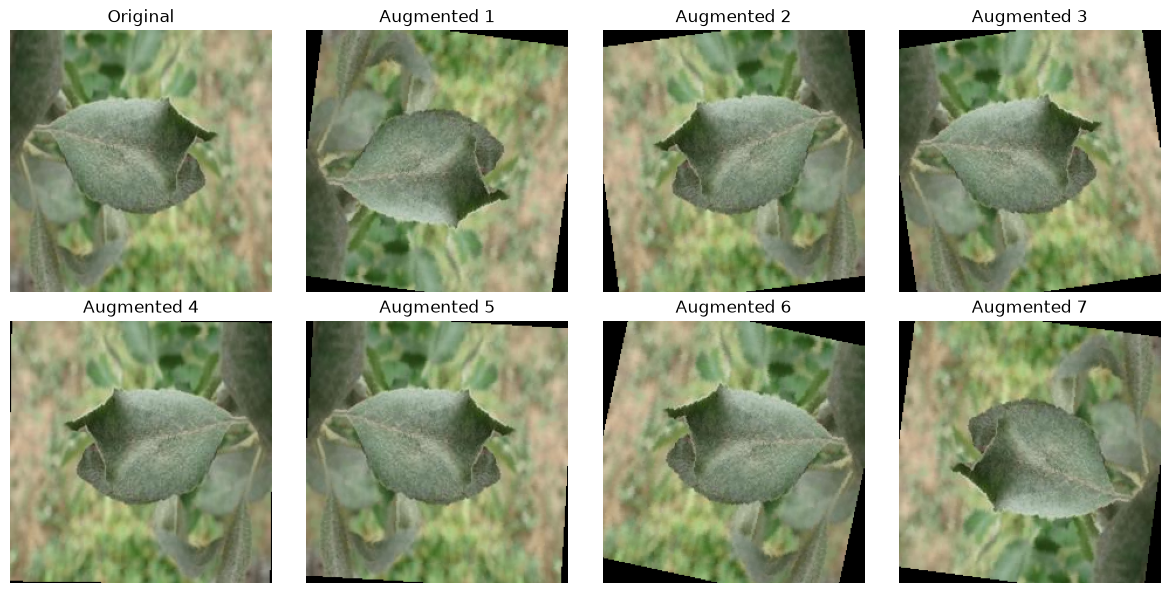

In [7]:
sample_path = IMAGE_DIR / train_data.iloc[0]["image"]

with Image.open(sample_path) as img:
    original_image = img.convert("RGB")

visual_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p = 0.5),
    transforms.RandomVerticalFlip(p = 0.5),
    transforms.RandomRotation(degrees=15)
])

plt.figure(figsize = (12, 6))

plt.subplot(2, 4, 1)
plt.imshow(original_image)
plt.title("Original")
plt.axis("off")

for i in range(2, 9):
    augmented_image = visual_transform(original_image)

    plt.subplot(2, 4, i)
    plt.imshow(augmented_image)
    plt.title(f"Augmented {i-1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
model = models.resnet18(weights = None)

model.fc = nn.Linear(
    model.fc.in_features, 6
)

model.load_state_dict(
    torch.load(
        "best_resnet18.pth",
        map_location='cpu',
        weights_only=True
    )
)

model = model.to(device)

In [11]:
for param in model.parameters():
    param.requires_grad = False

for param in model.layer4.parameters():
    param.requires_grad = True

for param in model.fc.parameters():
    param.requires_grad = True

In [12]:
for name, param in model.named_parameters():
    if param.requires_grad:
        print(name)

layer4.0.conv1.weight
layer4.0.bn1.weight
layer4.0.bn1.bias
layer4.0.conv2.weight
layer4.0.bn2.weight
layer4.0.bn2.bias
layer4.0.downsample.0.weight
layer4.0.downsample.1.weight
layer4.0.downsample.1.bias
layer4.1.conv1.weight
layer4.1.bn1.weight
layer4.1.bn1.bias
layer4.1.conv2.weight
layer4.1.bn2.weight
layer4.1.bn2.bias
fc.weight
fc.bias


In [13]:
criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr = 0.0001,
    weight_decay=0.01
)

In [15]:
from tqdm import tqdm

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            model.eval()

    total_loss = 0

    for images, labels in tqdm(loader, desc = "Training"):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        output = model(images)

        loss = criterion(output, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    return total_loss / len(loader.dataset)

In [16]:
def validate(model, loader, criterion, devcie):
    model.eval()

    total_loss = 0
    all_probs = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            output = model(images)
            loss = criterion(output, labels)

            probs = torch.sigmoid(output)

            total_loss += loss.item() * images.size(0)

            all_probs.append(probs.cpu().numpy())
            all_labels.append(labels.cpu().numpy())

    valid_loss = total_loss / len(loader.dataset)

    all_probs = np.concatenate(all_probs)
    all_labels = np.concatenate(all_labels)

    preds_05 = (all_probs >= 0.5).astype(int)
    preds_03 = (all_probs >= 0.3).astype(int)

    f1_05 = f1_score(
        all_labels, preds_05,
        average = "macro",
        zero_division=0
    )

    f1_03 = f1_score(
        all_labels, preds_03,
        average="macro",
        zero_division=0
    )

    return valid_loss, f1_05, f1_03

In [17]:
EPOCHS = 5

train_losses = []
valid_losses = []
f1_05_scores = []
f1_03_scores = []

best_f1 = -1

for epoch in range(EPOCHS):
    train_loss = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    valid_loss, f1_05, f1_03 = validate(
        model, valid_loader, criterion, device
    )

    train_losses.append(train_loss)
    valid_losses.append(valid_loss)
    f1_05_scores.append(f1_05)
    f1_03_scores.append(f1_03)

    print(
        f"Epoch [{epoch + 1} / {EPOCHS}]"
        f"Train Loss: {train_loss:.4f}"
        f"Valid Loss: {valid_loss:.4f}"
        f"F1(0.5): {f1_05:.4f}"
        f"F1(0.3): {f1_03:.4f}"
    )

    if f1_05 > best_f1:
        best_f1 = f1_05

        torch.save(
            model.state_dict(),
            "best_resnet18_augmented.pth"
        )

print(f"\nBest Valid Macro F1 (0.5): {best_f1:.4f}")

Training: 100%|██████████| 466/466 [00:42<00:00, 10.87it/s]


Epoch [1 / 5]Train Loss: 0.2244Valid Loss: 0.1979F1(0.5): 0.7252F1(0.3): 0.7704


Training: 100%|██████████| 466/466 [00:32<00:00, 14.56it/s]


Epoch [2 / 5]Train Loss: 0.1728Valid Loss: 0.1738F1(0.5): 0.7831F1(0.3): 0.7997


Training: 100%|██████████| 466/466 [00:31<00:00, 14.69it/s]


Epoch [3 / 5]Train Loss: 0.1547Valid Loss: 0.1502F1(0.5): 0.8131F1(0.3): 0.8223


Training: 100%|██████████| 466/466 [00:32<00:00, 14.35it/s]


Epoch [4 / 5]Train Loss: 0.1439Valid Loss: 0.1379F1(0.5): 0.8178F1(0.3): 0.8307


Training: 100%|██████████| 466/466 [00:32<00:00, 14.49it/s]


Epoch [5 / 5]Train Loss: 0.1368Valid Loss: 0.1431F1(0.5): 0.8264F1(0.3): 0.8349

Best Valid Macro F1 (0.5): 0.8264


In [18]:
from huggingface_hub import HfApi

api = HfApi()

repo_id = "leo10365/plant_pathology_2021_resnet18"

checkpoints = {
    "best_resnet18_augmented.pth":
    "checkpoints/augment/best_resnet18_augmented.pth"
}

for local_path, hub_path in checkpoints.items():
    api.upload_file(
        path_or_fileobj=local_path,
        path_in_repo=hub_path,
        repo_id=repo_id
    )

c:\Users\SSAFY\Desktop\ParkJaeWon\AI-practice\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Processing Files (1 / 1): 100%|██████████| 44.8MB / 44.8MB, 3.25MB/s  






Processing Files (1 / 1): 100%|██████████| 44.8MB / 44.8MB, 3.09MB/s  
New Data Upload: 100%|██████████| 34.8MB / 34.8MB, 2.51MB/s  
Validating: ██████████| 100%            


In [ ]:
# 다음 단계는 현재 모델이 어떤 이미지에서 틀리는지 분석하는 것